In [21]:
from statistics import LinearRegression

import torch
import numpy as np
import matplotlib.pyplot as plt

import os
os.makedirs('./images', exist_ok=True)


In [22]:
# 设置随机种子，保证结果可复现
torch.manual_seed(42)

# 生成100个样本点，真实关系为 y = 2x + 1 + 噪声
def generate_data(n_samples=100):
    # 生成 x，范围在 [0, 10] 之间
    x = torch.linspace(0, 10, n_samples).reshape(-1, 1)
    # 真实的权重和偏置
    w_true = 2.0
    b_true = 1.0
    # 生成 y，加上高斯噪声
    noise = torch.randn(n_samples, 1) * 0.5
    y = w_true * x + b_true + noise
    return x, y

x_data, y_data = generate_data()

print(f"x 的形状: {x_data.shape}")
print(f"y 的形状: {y_data.shape}")
print(f"前5个样本点:\n x: {x_data[:5].flatten()}\n y: {y_data[:5].flatten()}")

x 的形状: torch.Size([100, 1])
y 的形状: torch.Size([100, 1])
前5个样本点:
 x: tensor([0.0000, 0.1010, 0.2020, 0.3030, 0.4040])
 y: tensor([1.9635, 1.9457, 1.8544, 0.5533, 2.1473])


In [23]:
# TODO: 初始化参数 w 和 b
# 提示：使用 torch.tensor 创建张量

# 初始化权重 w，形状为 (1, 1)，初始值为 0
w = torch.tensor([[0.0]])
# 初始化偏置 b，形状为 (1,)，初始值为 0
b = torch.tensor([0.0])
print(f"初始 w: {w.item():.4f}, 初始 b: {b.item():.4f}")

初始 w: 0.0000, 初始 b: 0.0000


In [24]:
# TODO: 定义线性回归模型的前向计算
def linear_model(x, w, b):
    """
    线性回归模型: y = w * x + b

    参数:
        x: 输入数据，形状为 (n_samples, 1)
        w: 权重，形状为 (1, 1)
        b: 偏置，形状为 (1,)

    返回:
        预测值，形状为 (n_samples, 1)
    """
    return x @ w + b

In [25]:
# TODO: 定义均方误差损失函数
def mse_loss(y_pred, y_true):
    """
    均方误差损失函数: L = (1/n) * Σ(y_pred - y_true)²

    参数:
        y_pred: 预测值，形状为 (n_samples, 1)
        y_true: 真实值，形状为 (n_samples, 1)

    返回:
        损失值，一个标量
    """
    return torch.mean((y_pred - y_true) ** 2)

In [26]:
# TODO: 手动计算损失函数对 w 和 b 的梯度
def compute_gradients(x, y_true, y_pred):
    """
    计算损失函数对 w 和 b 的梯度。
    注意：这里我们不使用 PyTorch 的自动求导，而是手动实现梯度计算。

    提示：
        - 均方误差 L = (1/n) * Σ(y_pred - y_true)²
        - ∂L/∂w = (2/n) * Σ[(y_pred - y_true) * x]
        - ∂L/∂b = (2/n) * Σ[(y_pred - y_true)]

    参数:
        x: 输入数据，形状为 (n_samples, 1)
        y_true: 真实值，形状为 (n_samples, 1)
        y_pred: 预测值，形状为 (n_samples, 1)

    返回:
        grad_w: 损失函数对 w 的梯度
        grad_b: 损失函数对 b 的梯度
    """
    n = x.shape[0]  # 样本数量

    # 计算预测值与真实值的差值
    diff = y_pred - y_true

    # 计算梯度（注意形状匹配）
    grad_w = torch.mean(diff * x * 2 , dim=0,keepdim=True)
    grad_b = torch.mean(diff * 2 , dim=0)

    return grad_w, grad_b

In [27]:
# TODO: 实现梯度下降的参数更新
def update_parameters(w, b, grad_w, grad_b, learning_rate):
    """
    使用梯度下降更新参数
    w_new = w - lr * grad_w
    b_new = b - lr * grad_b

    参数:
        w: 当前权重
        b: 当前偏置
        grad_w: w 的梯度
        grad_b: b 的梯度
        learning_rate: 学习率

    返回:
        更新后的 w 和 b
    """
    w_new = w - learning_rate * grad_w
    b_new = b - learning_rate * grad_b
    return w_new, b_new

In [28]:
# TODO: 补全训练循环
def train(x, y, w, b, learning_rate, num_epochs):
    """
    训练线性回归模型

    参数:
        x: 训练数据
        y: 目标值
        w: 初始权重
        b: 初始偏置
        learning_rate: 学习率
        num_epochs: 训练轮数

    返回:
        训练过程中的损失记录, 训练好的 w 和 b
    """
    losses = []

    for epoch in range(num_epochs):
        # 1. 前向传播：计算预测值
        y_pred = linear_model(x, w, b)

        # 2. 计算损失
        loss = mse_loss(y_pred, y)
        losses.append(loss.item())

        # 3. 计算梯度
        grad_w, grad_b = compute_gradients(x, y, y_pred)

        # 4. 更新参数
        w, b = update_parameters(w, b, grad_w, grad_b, learning_rate)

        # 5. 每100轮打印一次损失
        if (epoch + 1) % 100 == 0:
            print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.6f}, w: {w.item():.4f}, b: {b.item():.4f}')

    return losses, w, b

In [29]:
# 设置超参数
learning_rate = 0.01
num_epochs = 1000

# 开始训练
losses, w_trained, b_trained = train(x_data, y_data, w, b, learning_rate, num_epochs)

print("\n===== 训练完成 =====")
print(f"真实的 w: 2.0, 学习到的 w: {w_trained.item():.4f}")
print(f"真实的 b: 1.0, 学习到的 b: {b_trained.item():.4f}")

Epoch [100/1000], Loss: 0.290928, w: 2.0636, b: 0.6021
Epoch [200/1000], Loss: 0.259282, w: 2.0375, b: 0.7756
Epoch [300/1000], Loss: 0.247584, w: 2.0216, b: 0.8811
Epoch [400/1000], Loss: 0.243261, w: 2.0120, b: 0.9452
Epoch [500/1000], Loss: 0.241663, w: 2.0061, b: 0.9842
Epoch [600/1000], Loss: 0.241072, w: 2.0026, b: 1.0079
Epoch [700/1000], Loss: 0.240854, w: 2.0004, b: 1.0223
Epoch [800/1000], Loss: 0.240773, w: 1.9991, b: 1.0310
Epoch [900/1000], Loss: 0.240743, w: 1.9983, b: 1.0364
Epoch [1000/1000], Loss: 0.240732, w: 1.9978, b: 1.0396

===== 训练完成 =====
真实的 w: 2.0, 学习到的 w: 1.9978
真实的 b: 1.0, 学习到的 b: 1.0396


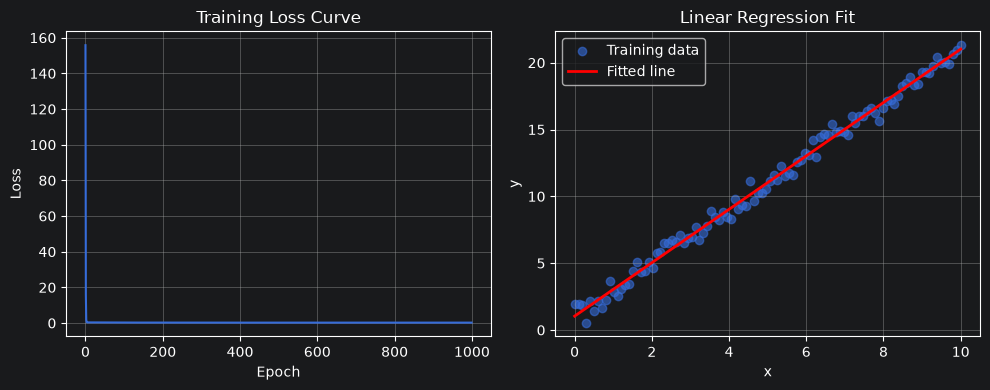

In [30]:
# 绘制损失下降曲线
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(losses)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss Curve')
plt.grid(True)

# 绘制拟合结果
plt.subplot(1, 2, 2)
plt.scatter(x_data.numpy(), y_data.numpy(), alpha=0.6, label='Training data')
plt.plot(x_data.numpy(), (w_trained * x_data + b_trained).numpy(),
         color='red', linewidth=2, label='Fitted line')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Linear Regression Fit')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('./images/linear_regression_manual_result.png', dpi=150)
plt.show()

# 以上所有填空均为本人手搓后交由deepseek检查改正

# Part 3
用pytorch拟合二元函数

In [37]:
import torch.nn as nn

# 设置样本点
def generate_data (n_samples=1000):

    x = torch.rand(n_samples, 2) * 10

    w_true = torch.tensor([3.0,2.0])
    b_true = 1.0

    noise = torch.randn(n_samples) * 0.3

    z = (x @ w_true + b_true + noise).reshape(n_samples, 1)

    return x, z

x_data, z_data = generate_data()
print(f"{x_data.shape}, {z_data.shape}")
print(f"[{float(x_data[:, 0].min()):.4f}, {float(x_data[:, 0].max()):.4f}]")
print(f"[{float(x_data[:, 1].min()):.4f}, {float(x_data[:, 1].max()):.4f}]")
print(f"z 的均值: {float(z_data.mean()):.4f}, z 的标准差: {float(z_data.std()):.4f}")

torch.Size([1000, 2]), torch.Size([1000, 1])
[0.0103, 9.9847]
[0.0117, 9.9786]
z 的均值: 26.0121, z 的标准差: 10.3729


In [38]:
# 定义线性回归模型的前向计算

class LR(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.linear = nn.Linear(in_features, out_features)

    def forward(self, x):
        return self.linear(x)

model = LR(2, 1)

print(model)

LR(
  (linear): Linear(in_features=2, out_features=1, bias=True)
)


In [39]:
# 均方误差损失函数

criterion = nn.MSELoss()

learning_rate = 0.01
num_epochs = 1000

# 优化器更新参数

optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

print(criterion)

MSELoss()


In [40]:
# 训练循环

def train(model, x_data, z_data, criterion, optimizer, num_epochs):
    losses = []
    for epoch in range(num_epochs):
        z_pred = model(x_data)

        loss = criterion(z_pred, z_data)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()


        losses.append(loss.item())

    return losses, model

In [41]:
losses, trained_model = train(model, x_data, z_data, criterion, optimizer, num_epochs)

w_1, w_2= [float(v) for v in trained_model.linear.weight.data.flatten()]
b_learnt = float(trained_model.linear.bias.item())

print(f"{w_1:.4f},{w_2:.4f}")
print(f"{b_learnt:.4f}")
print(f"{losses[-1]:.6f}")

3.0003,2.0006
1.0167
0.093488


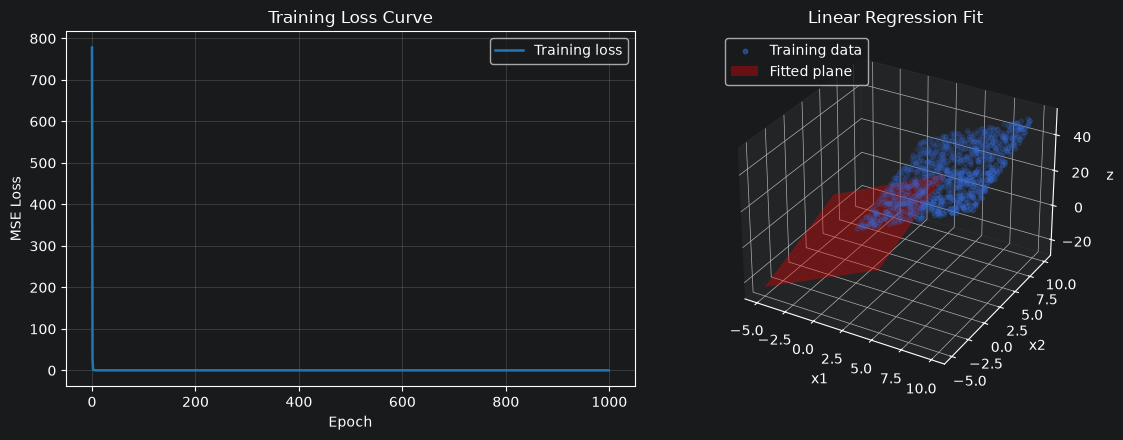

图片已保存: ./images/linear_regression_torch_result.png


In [42]:
# 绘制损失下降曲线 与 拟合效果（3D 散点 + 拟合平面）
fig = plt.figure(figsize=(12, 4.5))

# 左图：训练损失曲线
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(losses, color='#1f77b4', linewidth=1.8, label='Training loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('MSE Loss')
ax1.set_title('Training Loss Curve')
ax1.grid(True, alpha=0.3)
ax1.legend()

# 右图：拟合效果，样本散点 + 模型学到的平面
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.scatter(x_data[:, 0], x_data[:, 1], z_data.flatten(),
            s=10, alpha=0.5, label='Training data')
gx, gy = np.meshgrid(np.linspace(-5, 5, 20), np.linspace(-5, 5, 20))
gz = w_1 * gx + w_2 * gy + b_learnt
ax2.plot_surface(gx, gy, gz, color='red', alpha=0.35, edgecolor='none',
                 label='Fitted plane')
ax2.set_xlabel('x1')
ax2.set_ylabel('x2')
ax2.set_zlabel('z')
ax2.set_title('Linear Regression Fit')
ax2.legend(loc='upper left')

plt.tight_layout()
plt.savefig('./images/linear_regression_torch_result.png', dpi=150)
plt.show()

print("图片已保存: ./images/linear_regression_torch_result.png")